<a href="https://colab.research.google.com/github/fabiogalloppi-a11y/01NAEX/blob/main/week_06/CIFAR10_load_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-10 Subset – Data preparation and visualization


## Description

This notebook demonstrates how to:
- Load and preprocess a subset of the CIFAR-10 dataset (with selected classes).
- Create balanced training, validation, and test splits using NumPy.
- Build TensorFlow data loaders compatible with previous CNN notebooks (e.g., Cats vs Dogs).
- Visualize example images and inspect model predictions (correct and misclassified).

In [3]:
# Load the data:

# CIFAR-10 label names for reference
import numpy as np
import tensorflow as tf

cifar10_names = np.array([
    "airplane","automobile","bird","cat","deer",
    "dog","frog","horse","ship","truck"
])

# --- load raw CIFAR-10 ---
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = tf.keras.datasets.cifar10.load_data()
y_train_raw = y_train_raw.reshape(-1)
y_test_raw  = y_test_raw.reshape(-1)



170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 796s 5us/step


In [4]:
# Config
selected_classes = [0, 1, 2, 7]     # e.g. airplane, automobile, bird, horse
per_class_train = 500               # 4 classes → 4*500 = 2000 train
per_class_val   = 250               # 4*250 = 1000 val
per_class_test  = 250               # 4*250 = 1000 test
batch_size = 64
image_size = (180, 180)             # set to (180,180) to match Cats&Dogs models

seed = 42
rng = np.random.default_rng(seed)

In [5]:
# Selection of the subsets:

# --- Helper function: simple per-class selection ---
def select_subset(x, y, classes, n_per_class):
    idx = []
    for c in classes:
        ids = np.where(y == c)[0]
        rng.shuffle(ids)
        idx.extend(ids[:n_per_class])
    idx = np.array(idx)
    rng.shuffle(idx)
    return x[idx], y[idx]

# --- Select subsets ---
x_train_sel, y_train_sel = select_subset(x_train_raw, y_train_raw, selected_classes, per_class_train + per_class_val)
x_test,  y_test  = select_subset(x_test_raw,  y_test_raw,  selected_classes, per_class_test)

# --- Split train/val ---
n_train = len(selected_classes) * per_class_train
x_train, x_val = x_train_sel[:n_train], x_train_sel[n_train:]
y_train, y_val = y_train_sel[:n_train], y_train_sel[n_train:]

# --- Remap labels to 0..C-1 ---
class_map = {c: i for i, c in enumerate(selected_classes)}
y_train = np.vectorize(class_map.get)(y_train)
y_val   = np.vectorize(class_map.get)(y_val)
y_test  = np.vectorize(class_map.get)(y_test)

class_names = cifar10_names[selected_classes]
print("Classes:", class_names)

for name, data in zip(["train", "val", "test"], [(x_train, y_train), (x_val, y_val), (x_test, y_test)]):
    print(f"{name}: {len(data[0])} samples")



Classes: ['airplane' 'automobile' 'bird' 'horse']
train: 2000 samples
val: 1000 samples
test: 1000 samples


In [6]:
# plot the training progress:
def plot_history(history):
    history_dict = history.history
    print(history_dict.keys())

    from matplotlib import pyplot as plt

    # Plot training & validation accuracy values
    plt.plot(history.history['accuracy'])
    plt.plot(history.history['val_accuracy'])
    plt.title('Model accuracy')
    plt.ylabel('Accuracy')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

    # Plot training & validation loss values
    plt.plot(history.history['loss'])
    plt.plot(history.history['val_loss'])
    plt.title('Model loss')
    plt.ylabel('Loss')
    plt.xlabel('Epoch')
    plt.legend(['Train', 'Validation'], loc='upper left')
    plt.show()

In [7]:
# --- Create tf.data datasets ---
AUTOTUNE = tf.data.AUTOTUNE

def make_dataset(x, y, training=True):
    ds = tf.data.Dataset.from_tensor_slices((x, y))
    def preprocess(img, label):
        img = tf.image.resize(img, image_size)
        img = tf.cast(img, tf.float32) / 255.0
        return img, label
    ds = ds.map(preprocess, num_parallel_calls=AUTOTUNE)
    if training:
        ds = ds.shuffle(1000, seed=seed)
    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds = make_dataset(x_train, y_train, training=True)
val_ds   = make_dataset(x_val,   y_val,   training=False)
test_ds  = make_dataset(x_test,  y_test,  training=False)

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 22, 22, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 11, 11, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 391,588 (1.49 MB)

 Trainable params: 391,588 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 41s 718ms/step - accuracy: 0.4080 - loss: 1.2799 - val_accuracy: 0.5490 - val_loss: 1.1016
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step - accuracy: 0.5845 - loss: 1.0148 - val_accuracy: 0.5940 - val_loss: 1.0231
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 108ms/step - accuracy: 0.6460 - loss: 0.8916 - val_accuracy: 0.6480 - val_loss: 0.9046
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 95ms/step - accuracy: 0.6755 - loss: 0.8165 - val_accuracy: 0.6820 - val_loss: 0.8324
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - accuracy: 0.7045 - loss: 0.7286 - val_accuracy: 0.6730 - val_loss: 0.8558
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.7250 - loss: 0.6890 - val_accuracy: 0.7010 - val_loss: 0.8046
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 99ms/step - accuracy: 0.7590 - loss: 0.6391 - val_accuracy: 0.6600 - val_loss: 0.8157
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 105ms/step - accuracy: 0.7750 - loss: 0.5844 - val_accuracy: 0.706

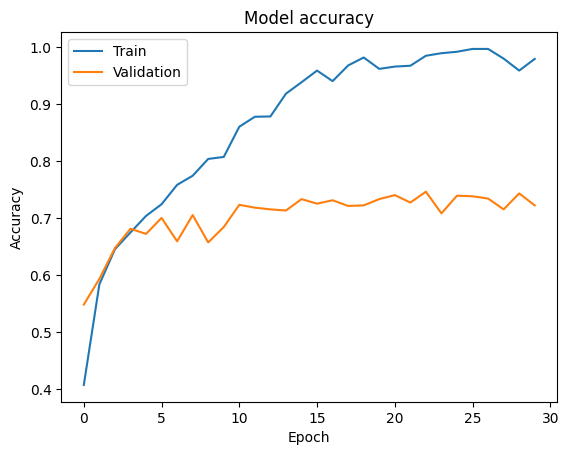

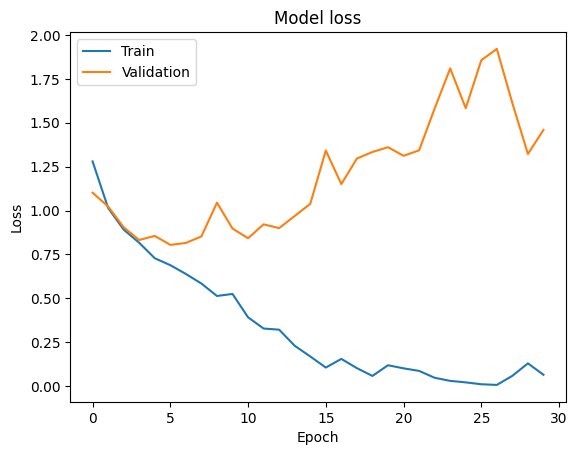

32/32 ━━━━━━━━━━━━━━━━━━━━ 6s 165ms/step - accuracy: 0.9885 - loss: 0.0382
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7230 - loss: 1.4594
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - accuracy: 0.7290 - loss: 1.5006
Training accuracy: 0.9884999990463257 
Train loss: 0.0382033996284008
Validation accuracy: 0.7229999899864197 
Val loss: 1.459432601928711
Test accuracy: 0.7289999723434448 
Test loss: 1.5006344318389893


In [8]:
# Set some of the hyperparameters:
do_early_stopping = False
max_epochs = 30
num_neur_1 = 256

hidden_activation = 'relu'
do_tensorboard = True
details = "cifar10_subset_bipyramidal"

###############################################
# Define the model architecture (Bipyramidal CNN)
import keras
from keras import layers

model = keras.Sequential([
    keras.Input(shape=(180, 180, 3)),

    keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(128, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(num_neur_1, activation=hidden_activation),
    keras.layers.Dense(4, activation='softmax') # 4 classes selected
])

model.summary()

import datetime
model_name = "cifar10_subset_bipyramid_cnn_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S") + '.keras'

# Configure the model:
model.compile(optimizer=keras.optimizers.Adam(learning_rate = 0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=[keras.metrics.SparseCategoricalAccuracy("accuracy")])

###############################################
# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_cifar/"+model_name, histogram_freq=1)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_ds, epochs=max_epochs, validation_data=val_ds, callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

# Evaluate the model on the training, validation and test sets
train_loss, train_acc = model.evaluate(train_ds)
val_loss, val_acc = model.evaluate(val_ds)
test_loss, test_acc = model.evaluate(test_ds)

print('Training accuracy:', train_acc, '\nTrain loss:', train_loss)
print('Validation accuracy:', val_acc, '\nVal loss:', val_loss)
print('Test accuracy:', test_acc, '\nTest loss:', test_loss)

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

**Observations:**
The model trains well but it starts to overfitting after 9-10 epochs, I will try some regularisation techniques.

In [9]:
import pandas as pd

try:
    results_df
except NameError:
    print("Inizializzazione di un nuovo dataframe per i risultati...")
    results_df = pd.DataFrame(columns=[
        "Model Name", "Details", "Test Accuracy", "Test Loss",
        "Train Accuracy", "Train Loss", "Time (s)", "Epochs"
    ])

if 'model_name' in globals() and model_name not in results_df["Model Name"].values:
    new_entry = {
        "Model Name" : model_name,
        "Details" : details,
        "Test Accuracy" : test_acc,
        "Test Loss" : test_loss,
        "Train Accuracy" : train_acc,
        "Train Loss" : train_loss,
        "Time (s)" : time_fit,
        "Epochs" : len(history.epoch) if 'history' in globals() else max_epochs
    }
    results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)
    print(f"Risultati per {model_name} salvati con successo!")

results_df

Inizializzazione di un nuovo dataframe per i risultati...
Risultati per cifar10_subset_bipyramid_cnn_20261108-175429.keras salvati con successo!


/tmp/ipykernel_759/495878987.py:23: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)


,Model Name,Details,Test Accuracy,Test Loss,Train Accuracy,Train Loss,Time (s),Epochs
0,cifar10_subset_bipyramid_cnn_20261108-175429.k...,cifar10_subset_bipyramidal,0.729,1.500634,0.9885,0.038203,147.787262,30


32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 123ms/step
Example probabilities: [4.2509496e-02 7.4309957e-01 3.4167206e-05 2.1435679e-01]
Predicted labels: [1 0 1 0 1 0 2 1 0 0]
True labels:      [1 2 1 0 1 1 2 1 1 0]
Number of misclassified images: 271 out of 1000 , accuracy 0.7289999723434448


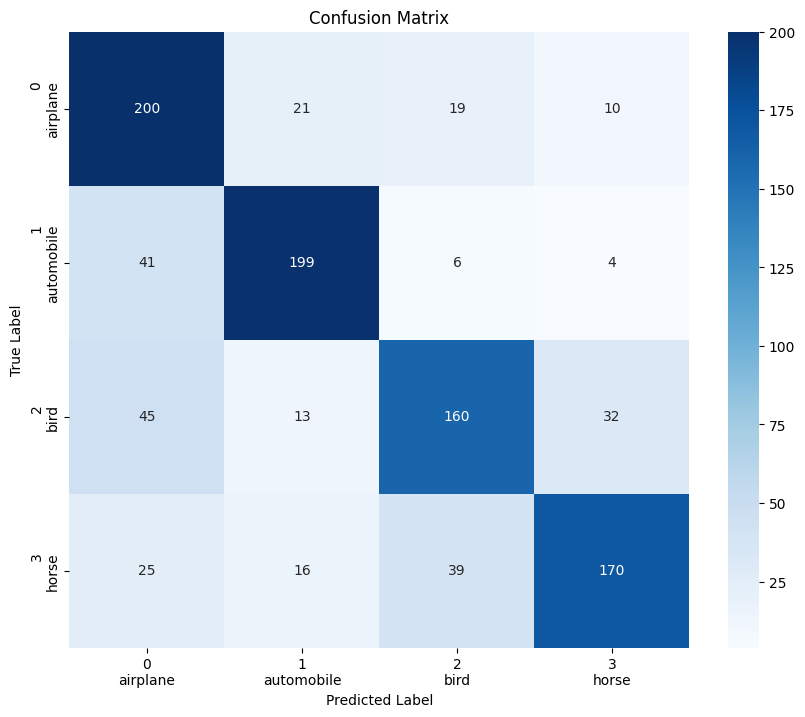

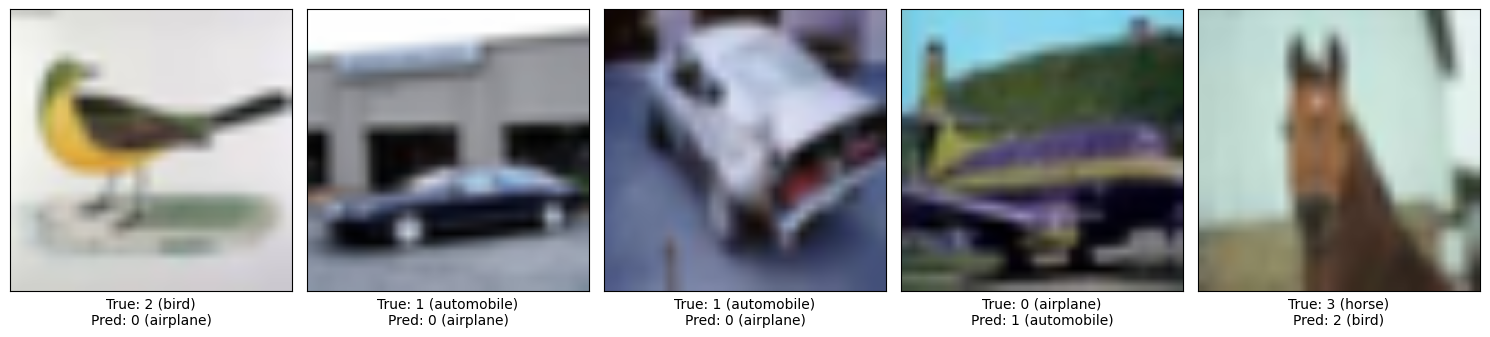

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

x_test_processed = []
y_test_labels = []
for imgs, labels in test_ds:
    x_test_processed.append(imgs.numpy())
    y_test_labels.append(labels.numpy())

x_test_processed = np.concatenate(x_test_processed, axis=0)
y_test_labels = np.concatenate(y_test_labels, axis=0)

y_pred_probs = model.predict(x_test_processed)
print("Example probabilities:", y_pred_probs[0])

y_pred = np.argmax(y_pred_probs, axis=1)

print("Predicted labels:", y_pred[:10])
print("True labels:     ", y_test_labels[:10])

misclassified_indices = np.where(y_pred != y_test_labels)[0]
num_misclassified = len(misclassified_indices)
print("Number of misclassified images:", num_misclassified,
      "out of", len(y_test_labels), ", accuracy", test_acc)

cm = confusion_matrix(y_test_labels, y_pred)
plt.figure(figsize=(10, 8))
labels_with_names = [f"{i}\n{name}" for i, name in enumerate(class_names)]
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels_with_names, yticklabels=labels_with_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

num_images_to_plot = 5
plt.figure(figsize=(15, 5))
for i in range(min(num_images_to_plot, len(misclassified_indices))):
    index = misclassified_indices[i]
    plt.subplot(1, num_images_to_plot, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)

    image = x_test_processed[index]
    plt.imshow(image)
    plt.xlabel(f"True: {y_test_labels[index]} ({class_names[y_test_labels[index]]})\n"
               f"Pred: {y_pred[index]} ({class_names[y_pred[index]]})")
plt.tight_layout()
plt.show()

**Early stopping**

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_10 (Conv2D)              │ (None, 180, 180, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 90, 90, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 90, 90, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 45, 45, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_12 (Conv2D)              │ (None, 45, 45, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_12 (MaxPooling2D) │ (None, 22, 22, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_13 (Conv2D)              │ (None, 22, 22, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_13 (MaxPooling2D) │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_14 (Conv2D)              │ (None, 11, 11, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_14 (MaxPooling2D) │ (None, 5, 5, 32)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 800)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       205,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │         1,028 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 391,588 (1.49 MB)

 Trainable params: 391,588 (1.49 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 12s 244ms/step - accuracy: 0.3675 - loss: 1.3260 - val_accuracy: 0.4830 - val_loss: 1.2435
Epoch 2/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.5655 - loss: 1.0914 - val_accuracy: 0.5430 - val_loss: 1.0763
Epoch 3/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 97ms/step - accuracy: 0.6160 - loss: 0.9489 - val_accuracy: 0.6290 - val_loss: 0.9580
Epoch 4/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 127ms/step - accuracy: 0.6765 - loss: 0.8388 - val_accuracy: 0.6590 - val_loss: 0.8628
Epoch 5/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 98ms/step - accuracy: 0.7125 - loss: 0.7453 - val_accuracy: 0.6820 - val_loss: 0.8097
Epoch 6/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 97ms/step - accuracy: 0.7340 - loss: 0.6766 - val_accuracy: 0.6700 - val_loss: 0.9175
Epoch 7/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 128ms/step - accuracy: 0.7555 - loss: 0.6334 - val_accuracy: 0.6720 - val_loss: 0.8503
Epoch 8/300
32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 96ms/step - accuracy: 0.7715 - loss: 0.5837 - val_accuracy

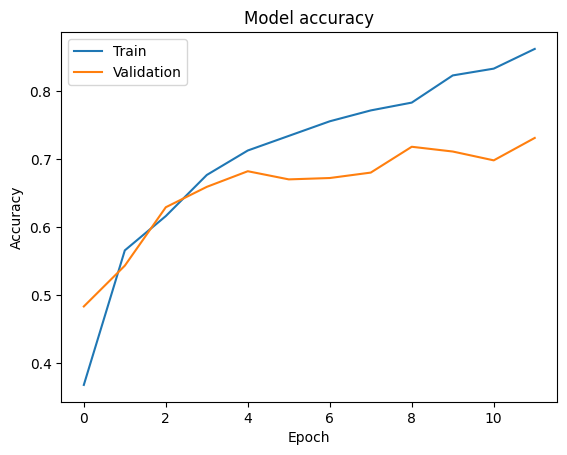

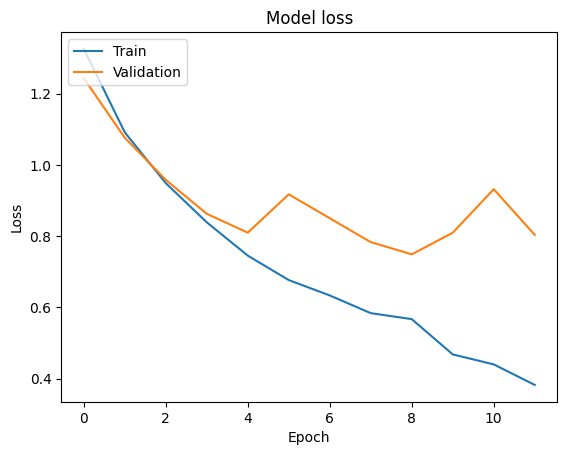

32/32 ━━━━━━━━━━━━━━━━━━━━ 3s 70ms/step - accuracy: 0.8350 - loss: 0.4463
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7180 - loss: 0.7489
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7170 - loss: 0.7474
Training accuracy: 0.8349999785423279 
Train loss: 0.4463284909725189
Validation accuracy: 0.7179999947547913 
Val loss: 0.7489152550697327
Test accuracy: 0.7170000076293945 
Test loss: 0.7474143505096436


In [13]:
# Set some of the hyperparameters:
do_early_stopping = True
max_epochs = 300
num_neur_1 = 256

hidden_activation = 'relu'
do_tensorboard = True
details = "cifar10_subset_bipyramidal_es"

###############################################
# Define the model architecture (Bipyramidal CNN)
import keras
from keras import layers

model = keras.Sequential([
    keras.Input(shape=(180, 180, 3)),

    keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(128, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    keras.layers.MaxPooling2D(pool_size=(2, 2)),

    keras.layers.Flatten(),

    keras.layers.Dense(num_neur_1, activation=hidden_activation),
    keras.layers.Dense(4, activation='softmax') # 4 classes selected
])

model.summary()

import datetime
model_name = "cifar10_subset_bipyramid_cnn_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S") + '.keras'

# Configure the model:
model.compile(optimizer=keras.optimizers.Adam(learning_rate = 0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=[keras.metrics.SparseCategoricalAccuracy("accuracy")])

###############################################
# Define callbacks (e.g., early stopping):
callbacks = []
if do_early_stopping:
    from keras.callbacks import EarlyStopping
    early_stopping = EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_tensorboard:
    from keras.callbacks import TensorBoard
    tensorboard_callback = TensorBoard(log_dir="./logs_cifar/"+model_name, histogram_freq=1)
    callbacks.append(tensorboard_callback)

################################################
# Train the model
import time
start_time = time.time()
history = model.fit(train_ds, epochs=max_epochs, validation_data=val_ds, callbacks=callbacks)
time_fit = time.time() - start_time

###############################
# Plot the training progress:
plot_history(history)

# Evaluate the model on the training, validation and test sets
train_loss, train_acc = model.evaluate(train_ds)
val_loss, val_acc = model.evaluate(val_ds)
test_loss, test_acc = model.evaluate(test_ds)

print('Training accuracy:', train_acc, '\nTrain loss:', train_loss)
print('Validation accuracy:', val_acc, '\nVal loss:', val_loss)
print('Test accuracy:', test_acc, '\nTest loss:', test_loss)

###############################
# Save the model:
import os
model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

In [14]:
# Aggiunge i risultati del modello con Early Stopping al DataFrame dei risultati
if 'model_name' in globals() and model_name not in results_df["Model Name"].values:
    new_entry = {
        "Model Name" : model_name,
        "Details" : details,
        "Test Accuracy" : test_acc,
        "Test Loss" : test_loss,
        "Train Accuracy" : train_acc,
        "Train Loss" : train_loss,
        "Time (s)" : time_fit,
        "Epochs" : len(history.epoch) if 'history' in globals() else max_epochs
    }
    results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)
    print(f"Risultati per {model_name} ({details}) salvati con successo!")

display(results_df)

Risultati per cifar10_subset_bipyramid_cnn_20261108-180623.keras (cifar10_subset_bipyramidal_es) salvati con successo!


,Model Name,Details,Test Accuracy,Test Loss,Train Accuracy,Train Loss,Time (s),Epochs
0,cifar10_subset_bipyramid_cnn_20261108-175429.k...,cifar10_subset_bipyramidal,0.729,1.500634,0.9885,0.038203,147.787262,30
1,cifar10_subset_bipyramid_aug_cnn_20261108-1757...,cifar10_subset_bipyramidal_augmented,0.737,0.764119,0.8160,0.490685,533.791029,30
2,cifar10_subset_bipyramid_cnn_20261108-180623.k...,cifar10_subset_bipyramidal_es,0.717,0.747414,0.8350,0.446328,53.809888,12


**Data augmentation**

Training with Data Augmentation...
Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 23s 403ms/step - accuracy: 0.3050 - loss: 1.3561 - val_accuracy: 0.4290 - val_loss: 1.2673
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 273ms/step - accuracy: 0.5165 - loss: 1.1737 - val_accuracy: 0.5250 - val_loss: 1.1097
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 317ms/step - accuracy: 0.5895 - loss: 1.0353 - val_accuracy: 0.5780 - val_loss: 1.0670
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 263ms/step - accuracy: 0.6105 - loss: 0.9427 - val_accuracy: 0.6230 - val_loss: 0.9300
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 21s 313ms/step - accuracy: 0.6490 - loss: 0.8653 - val_accuracy: 0.6330 - val_loss: 0.9652
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 289ms/step - accuracy: 0.6580 - loss: 0.8430 - val_accuracy: 0.6890 - val_loss: 0.8246
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 269ms/step - accuracy: 0.6680 - loss: 0.8362 - val_accuracy: 0.6520 - val_loss: 0.8914
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 316ms/step - accurac

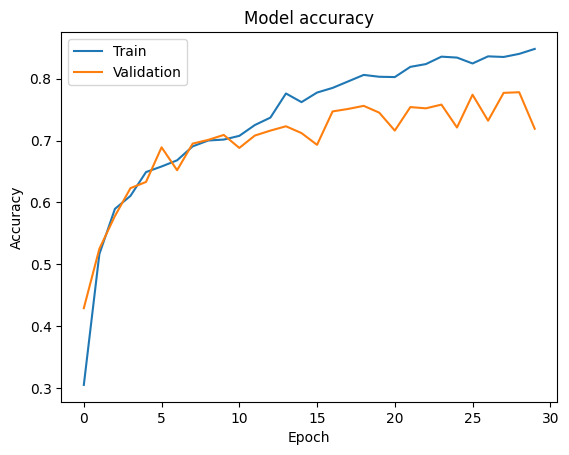

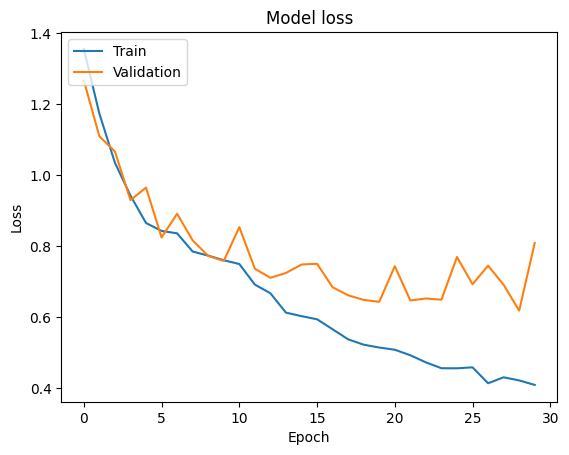

32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 254ms/step - accuracy: 0.8160 - loss: 0.4907
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.7190 - loss: 0.8091
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.7370 - loss: 0.7641
Training accuracy (Augmented): 0.8159999847412109
Test accuracy (Augmented): 0.7369999885559082


In [11]:
import tensorflow as tf
import keras
from keras import layers
import datetime
import time
import os

# Definiamo le variabili globali necessarie per rendere la cella auto-consistente
seed = 42
AUTOTUNE = tf.data.AUTOTUNE

data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal", seed=seed),
    layers.RandomRotation(0.1, seed=seed),
    layers.RandomZoom(0.1, seed=seed),
])

def make_augmented_dataset(x, y, training=True):
    ds = tf.data.Dataset.from_tensor_slices((x, y))

    def preprocess(img, label):
        img = tf.image.resize(img, image_size)
        img = tf.cast(img, tf.float32) / 255.0
        return img, label

    ds = ds.map(preprocess, num_parallel_calls=AUTOTUNE)

    if training:
        ds = ds.map(lambda x_img, y_lbl: (data_augmentation(x_img, training=True), y_lbl), num_parallel_calls=AUTOTUNE)
        ds = ds.shuffle(1000, seed=seed)

    ds = ds.batch(batch_size).prefetch(AUTOTUNE)
    return ds

train_ds_aug = make_augmented_dataset(x_train, y_train, training=True)
val_ds_aug = make_augmented_dataset(x_val, y_val, training=False)
test_ds_aug = make_augmented_dataset(x_test, y_test, training=False)

model = keras.Sequential([
    keras.Input(shape=(180, 180, 3)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(num_neur_1, activation=hidden_activation),
    layers.Dense(4, activation='softmax')
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=[keras.metrics.SparseCategoricalAccuracy("accuracy")])

details = "cifar10_subset_bipyramidal_augmented"
model_name = "cifar10_subset_bipyramid_aug_cnn_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S") + ".keras"

callbacks = []
if do_tensorboard:
    tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs_cifar/"+model_name, histogram_freq=1)
    callbacks.append(tensorboard_callback)

print("Training with Data Augmentation...")
start_time = time.time()
history = model.fit(train_ds_aug, epochs=max_epochs, validation_data=val_ds_aug, callbacks=callbacks)
time_fit = time.time() - start_time

plot_history(history)
train_loss, train_acc = model.evaluate(train_ds_aug)
val_loss, val_acc = model.evaluate(val_ds_aug)
test_loss, test_acc = model.evaluate(test_ds_aug)

print('Training accuracy (Augmented):', train_acc)
print('Test accuracy (Augmented):', test_acc)

model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

In [12]:
if 'model_name' in globals() and model_name not in results_df["Model Name"].values:
    new_entry = {
        "Model Name" : model_name,
        "Details" : details,
        "Test Accuracy" : test_acc,
        "Test Loss" : test_loss,
        "Train Accuracy" : train_acc,
        "Train Loss" : train_loss,
        "Time (s)" : time_fit,
        "Epochs" : 30 # max_epochs
    }
    results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

display(results_df)

,Model Name,Details,Test Accuracy,Test Loss,Train Accuracy,Train Loss,Time (s),Epochs
0,cifar10_subset_bipyramid_cnn_20261108-175429.k...,cifar10_subset_bipyramidal,0.729,1.500634,0.9885,0.038203,147.787262,30
1,cifar10_subset_bipyramid_aug_cnn_20261108-1757...,cifar10_subset_bipyramidal_augmented,0.737,0.764119,0.8160,0.490685,533.791029,30


**Observations:**
We can see that with data augmentation the overfitting starts later (around 22 epochs).

**Dropout**

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 26s 438ms/step - accuracy: 0.3595 - loss: 1.3081 - val_accuracy: 0.4790 - val_loss: 1.2022
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 17s 290ms/step - accuracy: 0.5295 - loss: 1.1162 - val_accuracy: 0.5460 - val_loss: 1.0822
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 307ms/step - accuracy: 0.5885 - loss: 1.0337 - val_accuracy: 0.5870 - val_loss: 1.0220
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 314ms/step - accuracy: 0.6185 - loss: 0.9605 - val_accuracy: 0.6400 - val_loss: 0.9182
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 274ms/step - accuracy: 0.6260 - loss: 0.9223 - val_accuracy: 0.6220 - val_loss: 0.9552
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 17s 296ms/step - accuracy: 0.6440 - loss: 0.8941 - val_accuracy: 0.6660 - val_loss: 0.8408
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 314ms/step - accuracy: 0.6680 - loss: 0.8434 - val_accuracy: 0.6670 - val_loss: 0.8671
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 16s 311ms/step - accuracy: 0.6680 - loss: 0.8405 - val_accu

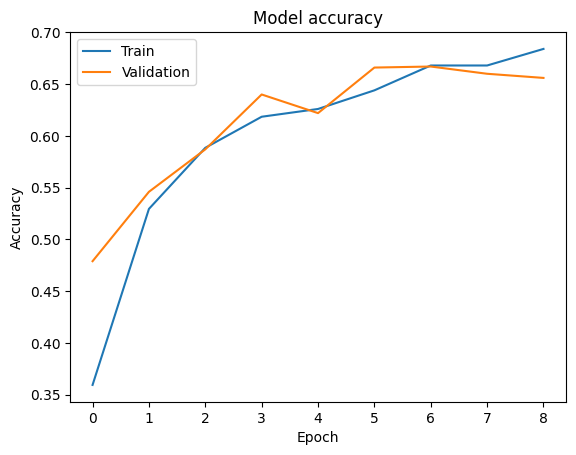

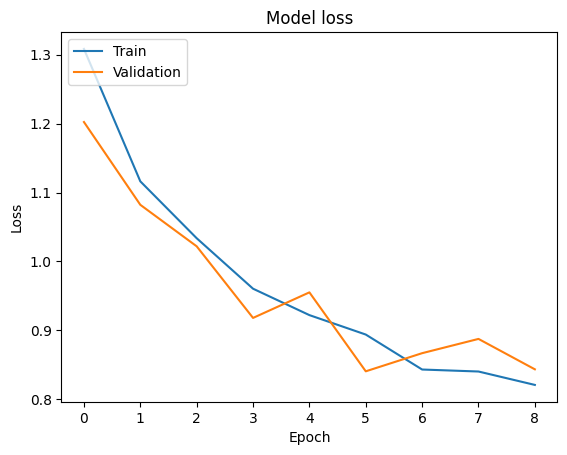

32/32 ━━━━━━━━━━━━━━━━━━━━ 14s 257ms/step - accuracy: 0.7060 - loss: 0.7749
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.6660 - loss: 0.8408
16/16 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.6700 - loss: 0.8148
Training accuracy: 0.7059999704360962 
Train loss: 0.7749192714691162
Test accuracy: 0.6700000166893005 
Test loss: 0.8147693872451782
Risultati per cifar10_subset_bipyramid_aug_dropout_cnn_20261108-180722.keras salvati con successo!


,Model Name,Details,Test Accuracy,Test Loss,Train Accuracy,Train Loss,Time (s),Epochs
0,cifar10_subset_bipyramid_cnn_20261108-175429.k...,cifar10_subset_bipyramidal,0.729,1.500634,0.9885,0.038203,147.787262,30
1,cifar10_subset_bipyramid_aug_cnn_20261108-1757...,cifar10_subset_bipyramidal_augmented,0.737,0.764119,0.8160,0.490685,533.791029,30
2,cifar10_subset_bipyramid_cnn_20261108-180623.k...,cifar10_subset_bipyramidal_es,0.717,0.747414,0.8350,0.446328,53.809888,12
3,cifar10_subset_bipyramid_aug_dropout_cnn_20261...,cifar10_subset_bipyramidal_aug_dropout,0.670,0.814769,0.7060,0.774919,160.206817,9


In [15]:
do_early_stopping = True
max_epochs = 30
num_neur_1 = 256
hidden_activation = 'relu'
do_tensorboard = True
details = "cifar10_subset_bipyramidal_aug_dropout"

train_ds_aug = make_augmented_dataset(x_train, y_train, training=True)
val_ds_aug = make_augmented_dataset(x_val, y_val, training=False)
test_ds_aug = make_augmented_dataset(x_test, y_test, training=False)

model = keras.Sequential([
    keras.Input(shape=(180, 180, 3)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(32, kernel_size=(3, 3), activation='relu', padding='same'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dropout(0.3, seed=seed),
    layers.Dense(num_neur_1, activation=hidden_activation),
    layers.Dropout(0.2, seed=seed),
    layers.Dense(4, activation='softmax')
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=[keras.metrics.SparseCategoricalAccuracy("accuracy")])

model_name = "cifar10_subset_bipyramid_aug_dropout_cnn_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S") + ".keras"

callbacks = []
if do_early_stopping:
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_tensorboard:
    tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs_cifar/"+model_name, histogram_freq=1)
    callbacks.append(tensorboard_callback)

start_time = time.time()
history = model.fit(train_ds_aug, epochs=max_epochs, validation_data=val_ds_aug, callbacks=callbacks)
time_fit = time.time() - start_time

plot_history(history)
train_loss, train_acc = model.evaluate(train_ds_aug)
val_loss, val_acc = model.evaluate(val_ds_aug)
test_loss, test_acc = model.evaluate(test_ds_aug)

print('Training accuracy:', train_acc, '\nTrain loss:', train_loss)
print('Test accuracy:', test_acc, '\nTest loss:', test_loss)

model_dir = "./models/"
if not os.path.exists(model_dir):
    os.makedirs(model_dir)
model.save(model_dir + model_name)

if 'model_name' in globals() and model_name not in results_df["Model Name"].values:
    new_entry = {
        "Model Name" : model_name,
        "Details" : details,
        "Test Accuracy" : test_acc,
        "Test Loss" : test_loss,
        "Train Accuracy" : train_acc,
        "Train Loss" : train_loss,
        "Time (s)" : time_fit,
        "Epochs" : len(history.epoch) if 'history' in globals() else max_epochs
    }
    results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)
    print(f"Risultati per {model_name} salvati con successo!")

display(results_df)

**Batch normalisation**

Epoch 1/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 20s 266ms/step - accuracy: 0.6050 - loss: 1.0091 - val_accuracy: 0.5300 - val_loss: 1.1598
Epoch 2/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 206ms/step - accuracy: 0.7120 - loss: 0.7195 - val_accuracy: 0.6530 - val_loss: 0.8479
Epoch 3/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 224ms/step - accuracy: 0.7510 - loss: 0.6344 - val_accuracy: 0.7210 - val_loss: 0.7544
Epoch 4/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 197ms/step - accuracy: 0.7755 - loss: 0.5803 - val_accuracy: 0.7380 - val_loss: 0.6519
Epoch 5/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 204ms/step - accuracy: 0.7975 - loss: 0.5147 - val_accuracy: 0.7580 - val_loss: 0.6277
Epoch 6/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 195ms/step - accuracy: 0.8145 - loss: 0.4874 - val_accuracy: 0.7610 - val_loss: 0.6196
Epoch 7/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 200ms/step - accuracy: 0.8275 - loss: 0.4545 - val_accuracy: 0.6850 - val_loss: 0.8547
Epoch 8/30
32/32 ━━━━━━━━━━━━━━━━━━━━ 7s 193ms/step - accuracy: 0.8405 - loss: 0.4000 - val_accuracy: 0

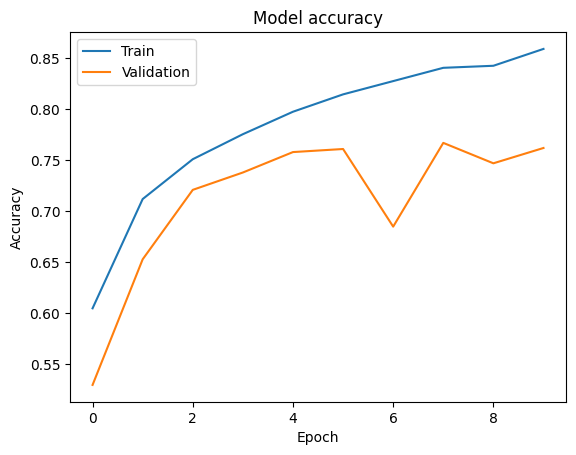

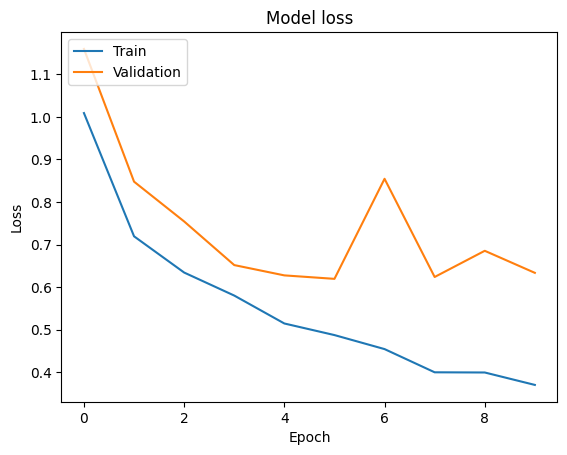

32/32 ━━━━━━━━━━━━━━━━━━━━ 2s 43ms/step - accuracy: 0.8450 - loss: 0.4092
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 39ms/step - accuracy: 0.7610 - loss: 0.6196
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - accuracy: 0.7490 - loss: 0.6429
BN Model - Training accuracy: 0.8450000286102295
BN Model - Test accuracy: 0.7490000128746033


,Model Name,Details,Test Accuracy,Test Loss,Train Accuracy,Train Loss,Time (s),Epochs
0,cifar10_subset_bipyramid_cnn_20261108-175429.k...,cifar10_subset_bipyramidal,0.729,1.500634,0.9885,0.038203,147.787262,30
1,cifar10_subset_bipyramid_aug_cnn_20261108-1757...,cifar10_subset_bipyramidal_augmented,0.737,0.764119,0.8160,0.490685,533.791029,30
2,cifar10_subset_bipyramid_cnn_20261108-180623.k...,cifar10_subset_bipyramidal_es,0.717,0.747414,0.8350,0.446328,53.809888,12
3,cifar10_subset_bipyramid_aug_dropout_cnn_20261...,cifar10_subset_bipyramidal_aug_dropout,0.670,0.814769,0.7060,0.774919,160.206817,9
4,cifar10_subset_bipyramid_bn_20261108-181018.keras,cifar10_subset_bipyramidal_batch_norm,0.749,0.642859,0.8450,0.409181,81.957301,10


In [16]:
do_early_stopping = True
max_epochs = 30
num_neur_1 = 256
hidden_activation = 'relu'
do_tensorboard = True
details = "cifar10_subset_bipyramidal_batch_norm"

train_ds_clean = make_dataset(x_train, y_train, training=True)
val_ds_clean   = make_dataset(x_val,   y_val,   training=False)
test_ds_clean  = make_dataset(x_test,  y_test,  training=False)

model = keras.Sequential([
    layers.Input(shape=(180, 180, 3)),

    layers.RandomFlip("horizontal", seed=seed),
    layers.RandomRotation(0.1, seed=seed),
    layers.RandomZoom(0.1, seed=seed),

    layers.Conv2D(32, kernel_size=(3, 3), padding='same'),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), padding='same'),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(128, kernel_size=(3, 3), padding='same'),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(64, kernel_size=(3, 3), padding='same'),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Conv2D(32, kernel_size=(3, 3), padding='same'),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.MaxPooling2D(pool_size=(2, 2)),

    layers.Flatten(),
    layers.Dense(num_neur_1),
    layers.BatchNormalization(momentum=0.9),
    layers.Activation('relu'),
    layers.Dense(4, activation='softmax')
])

model.compile(optimizer=keras.optimizers.Adam(learning_rate=0.001),
              loss=keras.losses.SparseCategoricalCrossentropy(),
              metrics=[keras.metrics.SparseCategoricalAccuracy("accuracy")])

model_name = "cifar10_subset_bipyramid_bn_" + datetime.datetime.now().strftime("%Y%m%d-%H%M%S") + ".keras"

callbacks = []
if do_early_stopping:
    early_stopping = keras.callbacks.EarlyStopping(monitor="val_loss", patience=4, restore_best_weights=True)
    callbacks.append(early_stopping)
if do_tensorboard:
    tensorboard_callback = keras.callbacks.TensorBoard(log_dir="./logs_cifar/"+model_name, histogram_freq=1)
    callbacks.append(tensorboard_callback)

start_time = time.time()
history = model.fit(train_ds_clean, epochs=max_epochs, validation_data=val_ds_clean, callbacks=callbacks)
time_fit = time.time() - start_time

plot_history(history)
train_loss, train_acc = model.evaluate(train_ds_clean)
val_loss, val_acc = model.evaluate(val_ds_clean)
test_loss, test_acc = model.evaluate(test_ds_clean)

print('BN Model - Training accuracy:', train_acc)
print('BN Model - Test accuracy:', test_acc)

model.save("./models/" + model_name)

if 'model_name' in globals() and model_name not in results_df["Model Name"].values:
    new_entry = {
        "Model Name" : model_name,
        "Details" : details,
        "Test Accuracy" : test_acc,
        "Test Loss" : test_loss,
        "Train Accuracy" : train_acc,
        "Train Loss" : train_loss,
        "Time (s)" : time_fit,
        "Epochs" : len(history.epoch) if 'history' in globals() else max_epochs
    }
    results_df = pd.concat([results_df, pd.DataFrame([new_entry])], ignore_index=True)

display(results_df)

**Observations:**
As we can see from the table above, the model which gave the best result in terms of accuracy, loss and time is the latter, meaning the one where the batch normalisation is introduced.

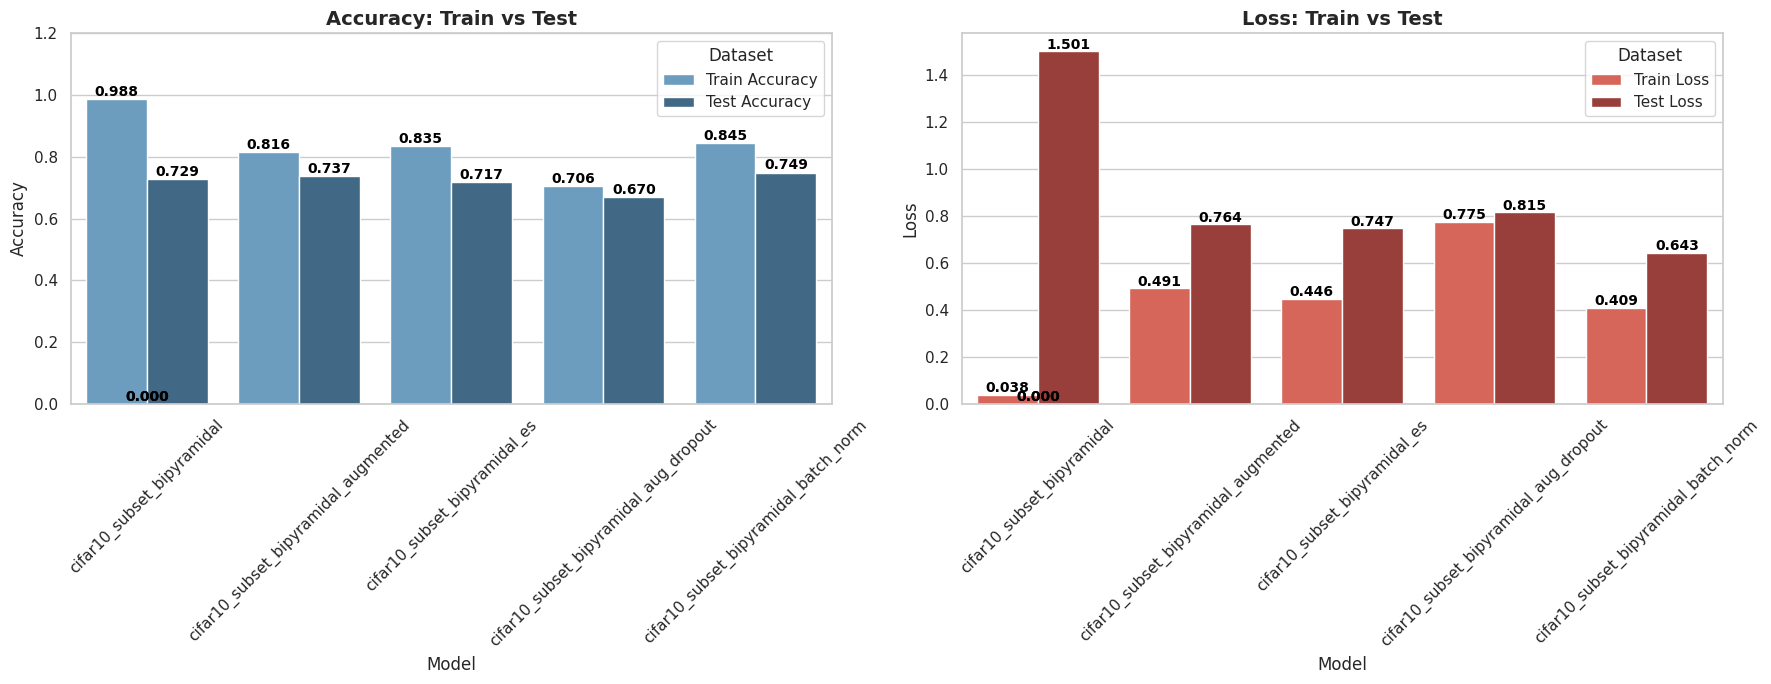

In [20]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 7))

df_melted_acc = results_df.melt(
    id_vars=["Details"],
    value_vars=["Train Accuracy", "Test Accuracy"],
    var_name="Dataset",
    value_name="Accuracy"
)
sns.barplot(ax=axes[0], data=df_melted_acc, x="Details", y="Accuracy", hue="Dataset", palette="Blues_d")
axes[0].set_title("Accuracy: Train vs Test", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Model", fontsize=12)
axes[0].set_ylabel("Accuracy", fontsize=12)
axes[0].set_ylim(0, 1.20)
axes[0].tick_params(axis='x', rotation=45)
for p in axes[0].patches:
    axes[0].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                      ha='center', va='baseline', fontsize=10, color='black', fontweight='semibold')

df_melted_loss = results_df.melt(
    id_vars=["Details"],
    value_vars=["Train Loss", "Test Loss"],
    var_name="Dataset",
    value_name="Loss"
)
sns.barplot(ax=axes[1], data=df_melted_loss, x="Details", y="Loss", hue="Dataset", palette="Reds_d")
axes[1].set_title("Loss: Train vs Test", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Model", fontsize=12)
axes[1].set_ylabel("Loss", fontsize=12)
axes[1].tick_params(axis='x', rotation=45)
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.3f}", (p.get_x() + p.get_width() / 2., p.get_height() + 0.01),
                    ha='center', va='baseline', fontsize=10, color='black', fontweight='semibold')

plt.tight_layout()
plt.show()
